# 06 Deteksi Anomali Teks

Menemukan teks yang menyimpang tanpa label. Contoh: komentar MBG yang disisipi teks luar topik, supaya skornya
bisa diukur.

**Peringatan:** skor pada anomali buatan cenderung jauh lebih tinggi daripada pada anomali sungguhan. Anggap
sebagai pembanding antar metode, bukan perkiraan kinerja asli.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Mendeteksi teks yang tidak wajar tanpa label |
| **Unit prediksi** | Satu komentar mendapat skor anomali |
| **Metrik** | AUC dan average precision pada injeksi sintetis |
| **Masalah terbesar** | Tidak ada contoh anomali asli, jadi kualitas hanya bisa diukur dari teks luar topik yang disisipkan. Anomali asli bisa saja berbeda sifatnya. |
| **Data contoh** | 4.795 komentar MBG, disisipi judul berita luar topik |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** soal meminta mendeteksi teks aneh, luar topik, spam, atau hoaks tanpa contoh berlabel. Kalau
yang dicari salinan teks yang mirip, pakai folder `07`. Kalau ada label, pakai folder `09`.

**Yang perlu diganti kalau datanya beda:**
- `load_data`. Di soal asli, injeksi hanya untuk menilai metode, dan skor akhir dihitung pada data tanpa injeksi.
- `CONTAMINATION`, perkiraan porsi anomali.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: embedding memakai TF-IDF + SVD, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
TEXT_COL = "Comment"
INJECT_SHARE = 0.05
CONTAMINATION = 0.05

SETTINGS = {"cepat": {"eval_seeds": [1, 2]}, "penuh": {"eval_seeds": [1, 2, 3, 4, 5]}}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'eval_seeds': [1, 2, 3, 4, 5]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Embedding teks.** Kalau pretrained boleh dipakai, teks diubah dengan multilingual-e5. Kalau
tidak boleh, `USE_PRETRAINED=False` memakai TF-IDF + SVD sebagai gantinya.

In [6]:
from sklearn.decomposition import TruncatedSVD  # noqa: E402
from sklearn.feature_extraction.text import TfidfVectorizer as _Tfidf  # noqa: E402
from sklearn.preprocessing import normalize as _l2  # noqa: E402
from transformers import AutoModel, AutoTokenizer  # noqa: E402


def tfidf_svd_embed(texts: list[str], dim: int = 256) -> np.ndarray:
    """Embedding tanpa pretrained: TF-IDF kata + SVD."""
    matrix = _Tfidf(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    dim = min(dim, matrix.shape[1] - 1, matrix.shape[0] - 1)
    return _l2(TruncatedSVD(dim, random_state=SEED).fit_transform(matrix))


@torch.inference_mode()
def e5_embed(texts: list[str], prefix: str = "query: ", batch_size: int = 64) -> np.ndarray:
    """Mean pooling multilingual-e5, hasil dinormalisasi L2."""
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR / "e5")
    model = AutoModel.from_pretrained(MODEL_DIR / "e5").to(DEVICE).eval().half()
    order = np.argsort([len(t) for t in texts])
    chunks = []
    for start in range(0, len(texts), batch_size):
        batch = [prefix + texts[i] for i in order[start : start + batch_size]]
        tokens = tokenizer(
            batch, padding=True, truncation=True, max_length=128, return_tensors="pt"
        ).to(DEVICE)
        hidden = model(**tokens).last_hidden_state
        mask = tokens["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        chunks.append(torch.nn.functional.normalize(pooled, dim=1).float().cpu().numpy())
    del model
    torch.cuda.empty_cache()
    vectors = np.empty((len(texts), chunks[0].shape[1]), dtype=np.float32)
    vectors[order] = np.vstack(chunks)
    return vectors


def embed_texts(texts: list[str]) -> np.ndarray:
    """Pilih embedding sesuai USE_PRETRAINED."""
    return e5_embed(texts) if USE_PRETRAINED else tfidf_svd_embed(texts)

## 4. EDA

Muat komentar sebagai data normal dan judul berita sebagai bahan anomali buatan.

In [7]:
import html  # noqa: E402

HTML_RE = re.compile(r"<[^>]+>")


def tidy(text: str) -> str:
    return clean_text(HTML_RE.sub(" ", html.unescape(str(text))))


comments = pd.read_csv(find_file("comment_data.csv"))[TEXT_COL].dropna().map(tidy)
comments = (
    comments[comments.str.split().str.len() >= 3]
    .drop_duplicates()
    .head(N_ROWS)
    .reset_index(drop=True)
)
news = pd.read_csv(find_file("indonesian-news-title.csv"))
news = news[news["category"].isin(["oto", "travel", "food", "inet"])]["title"].dropna().map(tidy)
print(f"komentar={len(comments)} | bahan berita luar topik={len(news)}")
text_profile(comments)

komentar=4795 | bahan berita luar topik=20804


baris                4795.0
kosong                  0.0
duplikat_persis_%       0.0
kata_median            18.0
kata_p95               90.0
kata_maks            1485.0
ada_url_%               0.0
ada_emoji_%            13.3
dtype: float64

Sebaran panjang komentar. Komentar sangat panjang sering berisi promosi atau tempelan.

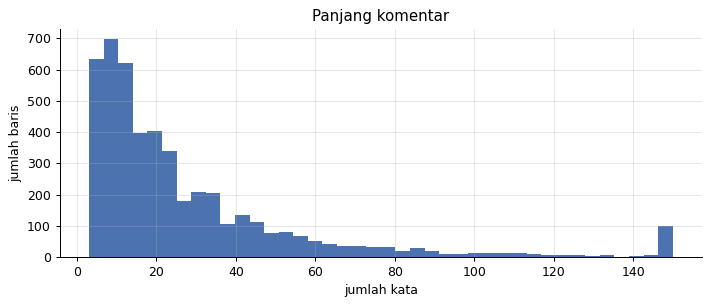

komentar berisi tautan: 0.0 %


In [8]:
lengths = comments.str.split().str.len()
fig, ax = plt.subplots()
lengths.clip(upper=150).plot.hist(bins=40, ax=ax, color="#4C72B0")
ax.set(title="Panjang komentar", xlabel="jumlah kata", ylabel="jumlah baris")
plt.tight_layout()
plt.show()
print("komentar berisi tautan:", round(100 * comments.str.contains("http|www").mean(), 1), "%")

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Komentar berisi tautan 0% | Pola tautan tidak bisa dijadikan sinyal |
| Slang dan tanda baca bisa jadi sinyal | Teks hanya dibersihkan ringan |
| Hasil bisa bergantung pada injeksi | Pakai beberapa seed, lalu laporkan rata-rata dan simpangan |

## 5. Preprocessing

Teks dibersihkan ringan dan tidak dinormalisasi. Slang, tanda seru, dan pola penulisan yang tidak biasa
justru termasuk sinyal anomali. Embedding dihitung sekali untuk komentar dan bahan injeksi.

In [9]:
all_news = (
    news.drop_duplicates().sample(n=min(1500, len(news)), random_state=SEED).reset_index(drop=True)
)
all_texts = comments.tolist() + all_news.tolist()
with stage("embedding"):
    all_vectors = embed_texts(all_texts)
comment_vectors = all_vectors[: len(comments)]
news_vectors = all_vectors[len(comments) :]
print("embedding:", all_vectors.shape)

[waktu] embedding: 43 detik
embedding: (6295, 768)


## 6. Validasi

**Injeksi sintetis:** sebagian judul berita luar topik disisipkan, lalu dilihat apakah metode menaruhnya di
peringkat atas. Beberapa seed injeksi dipakai, supaya hasilnya tidak bergantung pada satu undian. Metrik: AUC,
average precision (AP), dan recall pada `CONTAMINATION` teratas.

In [10]:
from sklearn.ensemble import IsolationForest  # noqa: E402
from sklearn.metrics import average_precision_score  # noqa: E402
from sklearn.metrics import roc_auc_score as auc  # noqa: E402
from sklearn.neighbors import LocalOutlierFactor  # noqa: E402


def recall_at_share(target_flags: np.ndarray, scores: np.ndarray, share: float) -> float:
    top = np.argsort(-scores)[: int(share * len(scores))]
    return float(target_flags[top].sum() / max(target_flags.sum(), 1))


assert recall_at_share(np.array([1, 0, 0, 0]), np.array([0.9, 0.1, 0.2, 0.3]), 0.25) == 1.0


def inject(seed: int) -> tuple[np.ndarray, np.ndarray]:
    """Gabungkan komentar dengan sebagian berita. Kembalikan vektor dan penanda injeksi."""
    rng = np.random.default_rng(seed)
    n_inject = int(INJECT_SHARE * len(comment_vectors))
    picks = rng.choice(len(news_vectors), n_inject, replace=False)
    vectors = np.vstack([comment_vectors, news_vectors[picks]])
    flags = np.array([0] * len(comment_vectors) + [1] * n_inject)
    order = rng.permutation(len(vectors))
    return vectors[order], flags[order]


results: list[dict] = []


def evaluate(name: str, score_fn) -> None:
    """Rata-rata skor antar seed injeksi."""
    rows = []
    for seed in SETTINGS["eval_seeds"]:
        vectors, flags = inject(seed)
        scores = score_fn(vectors, seed)
        rows.append(
            {
                "auc": auc(flags, scores),
                "ap": average_precision_score(flags, scores),
                "recall_atas": recall_at_share(flags, scores, CONTAMINATION),
            }
        )
    frame = pd.DataFrame(rows)
    results.append(
        {"metode": name, **frame.mean().round(4).to_dict(), "auc_sd": round(frame["auc"].std(), 4)}
    )
    print(results[-1])

## 7. Baseline

Jarak ke rata-rata seluruh data: makin jauh, makin aneh. Sederhana dan tanpa parameter.

In [11]:
def centroid_distance(vectors: np.ndarray, _seed: int) -> np.ndarray:
    return 1 - vectors @ (vectors.mean(0) / np.linalg.norm(vectors.mean(0)))


evaluate("jarak_ke_pusat", centroid_distance)

{'metode': 'jarak_ke_pusat', 'auc': 0.8792, 'ap': 0.3287, 'recall_atas': 0.3582, 'auc_sd': 0.0059}


## 8. Model Utama

**IsolationForest** mengisolasi titik yang mudah dipisahkan. **LOF** melihat kerapatan lokal, jadi lebih cocok
kalau data normal punya beberapa kelompok. **kNN** memakai jarak ke tetangga terdekat.

In [12]:
def isolation_scores(vectors: np.ndarray, seed: int) -> np.ndarray:
    model = IsolationForest(n_estimators=300, random_state=seed, n_jobs=-1).fit(vectors)
    return -model.score_samples(vectors)


def lof_scores(vectors: np.ndarray, _seed: int) -> np.ndarray:
    model = LocalOutlierFactor(n_neighbors=30, metric="cosine", n_jobs=-1).fit(vectors)
    return -model.negative_outlier_factor_


def knn_scores(vectors: np.ndarray, _seed: int) -> np.ndarray:
    model = LocalOutlierFactor(n_neighbors=10, metric="cosine", n_jobs=-1).fit(vectors)
    distance, _ = model.kneighbors(vectors)
    return distance.mean(1)


with stage("model"):
    evaluate("isolation_forest", isolation_scores)
    evaluate("lof", lof_scores)
    evaluate("knn", knn_scores)

{'metode': 'isolation_forest', 'auc': 0.8729, 'ap': 0.3237, 'recall_atas': 0.3724, 'auc_sd': 0.0144}


{'metode': 'lof', 'auc': 0.8974, 'ap': 0.3303, 'recall_atas': 0.4042, 'auc_sd': 0.0092}


{'metode': 'knn', 'auc': 0.946, 'ap': 0.5257, 'recall_atas': 0.6075, 'auc_sd': 0.0099}
[waktu] model: 13 detik


## 9. Post-processing

Gabungkan metode dengan rata-rata peringkat, karena skala skornya berbeda. Rata-rata tanpa bobot dipakai
karena tidak ada label untuk memfit bobot.

In [13]:
METHODS = {"isolation_forest": isolation_scores, "lof": lof_scores, "knn": knn_scores}


def rank_average(vectors: np.ndarray, seed: int) -> np.ndarray:
    ranks = [pd.Series(fn(vectors, seed)).rank(pct=True).to_numpy() for fn in METHODS.values()]
    return np.mean(ranks, axis=0)


evaluate("gabungan_peringkat", rank_average)

{'metode': 'gabungan_peringkat', 'auc': 0.9414, 'ap': 0.4215, 'recall_atas': 0.4703, 'auc_sd': 0.0047}


## 10. Post-analysis

**Tabel perbandingan.** Selisih di dalam `auc_sd` jangan dianggap perbaikan nyata.

In [14]:
result_table = pd.DataFrame(results).sort_values("auc", ascending=False)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,metode,auc,ap,recall_atas,auc_sd
3,knn,0.9460,0.5257,0.6075,0.0099
4,gabungan_peringkat,0.9414,0.4215,0.4703,0.0047
2,lof,0.8974,0.3303,0.4042,0.0092
0,jarak_ke_pusat,0.8792,0.3287,0.3582,0.0059
1,isolation_forest,0.8729,0.3237,0.3724,0.0144


**Anomali sungguhan.** Metode dijalankan pada komentar asli **tanpa injeksi**. Baca hasil teratas secara manual.
Ini satu-satunya gambaran kualitas yang sebenarnya.

In [15]:
real_scores = rank_average(comment_vectors, SEED)
top_real = pd.DataFrame({"komentar": comments.str[:110], "skor": real_scores.round(3)}).sort_values(
    "skor", ascending=False
)
top_real.head(10)

,komentar,skor
1844,the man behind the gun.,1.000
1007,"food is medicine, positive or negative?",0.999
4707,buah apa yang paling manis?,0.999
839,berarti itu egois,0.998
2855,channel andalan saya capt🔥,0.998
1784,belajar investasi dari warren buffet,0.998
3616,right man on the right place.....,0.997
1041,puwasya dimana boss,0.997
1515,super double mantap,0.997
3594,ngomong by data buka berdasarkan film dan katanya,0.997


**Sebaran skor** untuk memilih batas.

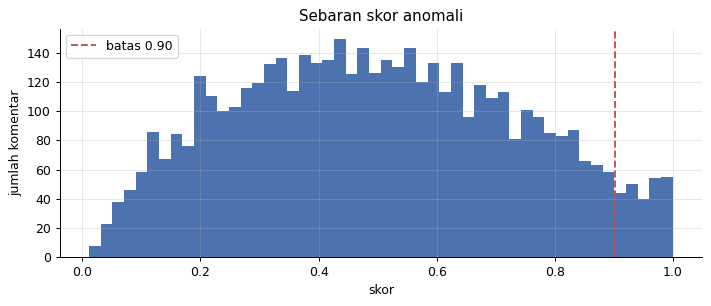

In [16]:
threshold = np.quantile(real_scores, 1 - CONTAMINATION)
fig, ax = plt.subplots()
ax.hist(real_scores, bins=50, color="#4C72B0")
ax.axvline(threshold, color="#C44E52", ls="--", label=f"batas {threshold:.2f}")
ax.set(title="Sebaran skor anomali", xlabel="skor", ylabel="jumlah komentar")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [17]:
pd.DataFrame(
    {
        "id": comments.index,
        "skor": real_scores.round(4),
        "anomali": (real_scores >= threshold).astype(int),
    }
).to_csv(RESULT_DIR / "submission.csv", index=False)
run_summary(
    "anomali_teks",
    len(comments),
    {r["metode"]: {"auc": r["auc"], "ap": r["ap"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=anomali_teks mode=penuh n_rows=4795 total_detik=80 gpu=True
{
 "jarak_ke_pusat": {
  "auc": 0.8792,
  "ap": 0.3287
 },
 "isolation_forest": {
  "auc": 0.8729,
  "ap": 0.3237
 },
 "lof": {
  "auc": 0.8974,
  "ap": 0.3303
 },
 "knn": {
  "auc": 0.946,
  "ap": 0.5257
 },
 "gabungan_peringkat": {
  "auc": 0.9414,
  "ap": 0.4215
 }
}


**Poin untuk presentasi**

- kNN pada embedding terbaik: AUC 0,946 dan average precision 0,5257.
- Gabungan peringkat sedikit lebih rendah (AUC 0,9414), tapi simpangannya lebih kecil (0,0047 dibanding 0,0099). Kalau metriknya AP, kNN jelas lebih baik.
- Isolation Forest paling lemah di sini (AUC 0,8729), walaupun paling populer.
- Komentar peringkat atas banyak berbahasa Inggris atau tidak nyambung. Ini cocok dipakai untuk membersihkan data sebelum modelling.